In [1]:
# 1. Imports
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


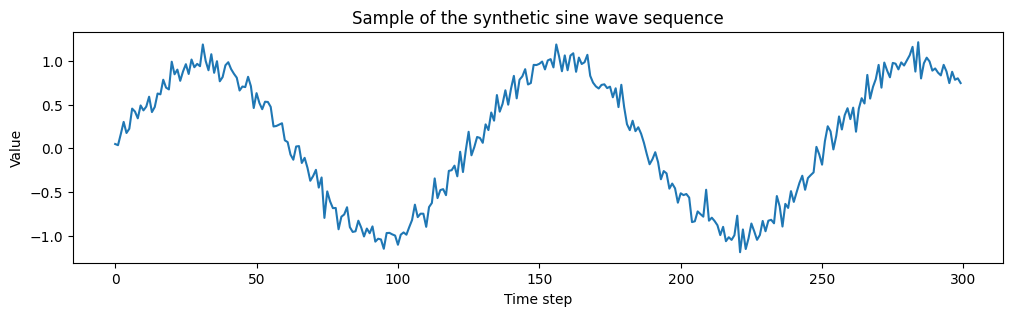

In [2]:
np.random.seed(42)

# Generate a sine wave with a small amount of noise
n_points = 2000
x = np.linspace(0, 100, n_points)
series = np.sin(x) + 0.1 * np.random.randn(n_points)

plt.figure(figsize=(12, 3))
plt.plot(series[:300])
plt.title("Sample of the synthetic sine wave sequence")
plt.xlabel("Time step")
plt.ylabel("Value")
plt.show()


In [3]:

window_size = 20

def make_windows(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

X, y = make_windows(series, window_size)

# RNN expects input shape (samples, timesteps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))
print("X shape:", X.shape, "y shape:", y.shape)


X shape: (1980, 20, 1) y shape: (1980,)


In [4]:

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Train samples:", X_train.shape[0], "Test samples:", X_test.shape[0])


Train samples: 1584 Test samples: 396


In [5]:
model = keras.Sequential([
    layers.Input(shape=(window_size, 1)),
    layers.SimpleRNN(32, activation="tanh", return_sequences=True),
    layers.SimpleRNN(16, activation="tanh"),
    layers.Dense(1)
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 20, 32)         │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 16)             │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,889 (7.38 KB)

 Trainable params: 1,889 (7.38 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=32,
    verbose=2
)


Epoch 1/30
50/50 - 5s - 101ms/step - loss: 0.0539 - mae: 0.1695 - val_loss: 0.0160 - val_mae: 0.1007
Epoch 2/30
50/50 - 1s - 11ms/step - loss: 0.0163 - mae: 0.1018 - val_loss: 0.0144 - val_mae: 0.0949
Epoch 3/30
50/50 - 1s - 11ms/step - loss: 0.0149 - mae: 0.0973 - val_loss: 0.0155 - val_mae: 0.0985
Epoch 4/30
50/50 - 1s - 12ms/step - loss: 0.0147 - mae: 0.0971 - val_loss: 0.0143 - val_mae: 0.0939
Epoch 5/30
50/50 - 1s - 12ms/step - loss: 0.0141 - mae: 0.0950 - val_loss: 0.0135 - val_mae: 0.0911
Epoch 6/30
50/50 - 1s - 11ms/step - loss: 0.0140 - mae: 0.0944 - val_loss: 0.0126 - val_mae: 0.0877
Epoch 7/30
50/50 - 1s - 12ms/step - loss: 0.0134 - mae: 0.0926 - val_loss: 0.0122 - val_mae: 0.0859
Epoch 8/30
50/50 - 1s - 11ms/step - loss: 0.0129 - mae: 0.0911 - val_loss: 0.0120 - val_mae: 0.0861
Epoch 9/30
50/50 - 1s - 12ms/step - loss: 0.0134 - mae: 0.0924 - val_loss: 0.0123 - val_mae: 0.0873
Epoch 10/30
50/50 - 1s - 11ms/step - loss: 0.0128 - mae: 0.0909 - val_loss: 0.0121 - val_mae: 0.086

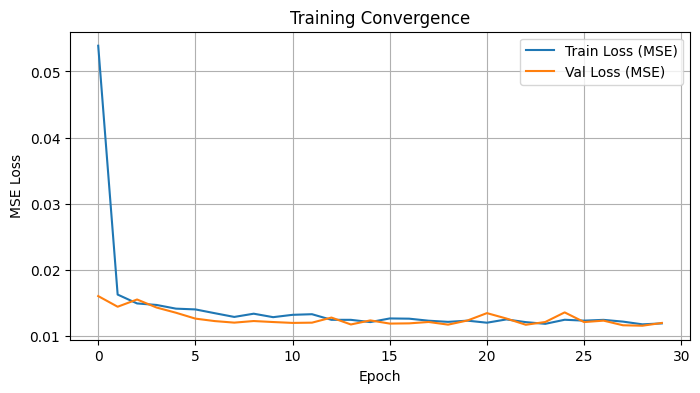

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Val Loss (MSE)')
plt.title('Training Convergence')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()


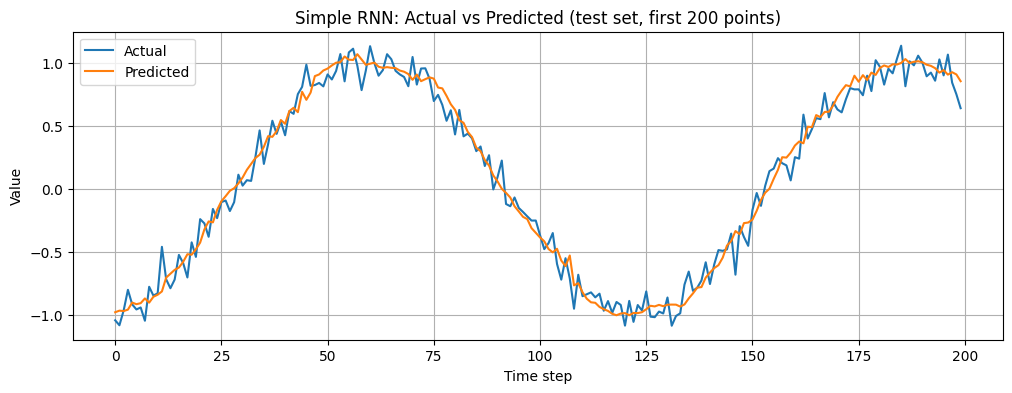

Test MSE: 0.01197 | Test MAE: 0.08713


In [8]:
# Predict on the test set
y_pred = model.predict(X_test, verbose=0).flatten()

plt.figure(figsize=(12, 4))
plt.plot(y_test[:200], label='Actual')
plt.plot(y_pred[:200], label='Predicted')
plt.title('Simple RNN: Actual vs Predicted (test set, first 200 points)')
plt.xlabel('Time step')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"Test MSE: {test_loss:.5f} | Test MAE: {test_mae:.5f}")


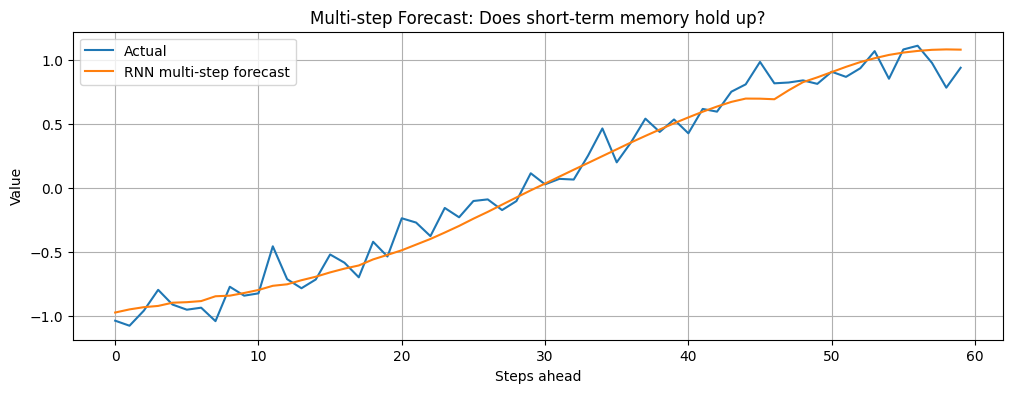

In [9]:
# Use the model to forecast multiple steps ahead, feeding its own predictions back in
def forecast(model, seed_sequence, n_steps, window_size):
    seq = list(seed_sequence)
    for _ in range(n_steps):
        window = np.array(seq[-window_size:]).reshape(1, window_size, 1)
        next_val = model.predict(window, verbose=0)[0, 0]
        seq.append(next_val)
    return np.array(seq[len(seed_sequence):])

seed = series[split:split + window_size]
forecast_steps = 60
predicted_future = forecast(model, seed, forecast_steps, window_size)
actual_future = series[split + window_size: split + window_size + forecast_steps]

plt.figure(figsize=(12, 4))
plt.plot(actual_future, label='Actual')
plt.plot(predicted_future, label='RNN multi-step forecast')
plt.title('Multi-step Forecast: Does short-term memory hold up?')
plt.xlabel('Steps ahead')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()


In [10]:
print(f"""
ANALYSIS: Simple RNN — Short-Term Dependency Learning
------------------------------------------------------
Test MSE (single-step prediction): {test_loss:.5f}
Test MAE (single-step prediction): {test_mae:.5f}

The model tracks the sine wave's short-term cyclical pattern well in
single-step prediction, since the window of {window_size} steps is enough
to capture local phase information. In multi-step forecasting, prediction
errors compound over time as the model's own (imperfect) outputs become its
next inputs, illustrating that a plain SimpleRNN captures short-term
dependencies effectively but struggles with longer-horizon dependencies —
a key motivation for more advanced architectures like LSTM and GRU.
""")



ANALYSIS: Simple RNN — Short-Term Dependency Learning
------------------------------------------------------
Test MSE (single-step prediction): 0.01197
Test MAE (single-step prediction): 0.08713

The model tracks the sine wave's short-term cyclical pattern well in
single-step prediction, since the window of 20 steps is enough
to capture local phase information. In multi-step forecasting, prediction
errors compound over time as the model's own (imperfect) outputs become its
next inputs, illustrating that a plain SimpleRNN captures short-term
dependencies effectively but struggles with longer-horizon dependencies —
a key motivation for more advanced architectures like LSTM and GRU.

